In [238]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import chi2
from sklearn.preprocessing import LabelEncoder
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# drop nulls from jobSat

In [239]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/MLmilestone2/train_data.csv')

print(data.shape)
data = data.dropna(subset=['JobSatLevel'])
print(data.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_31035/2977422011.py:5: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('/content/drive/MyDrive/MLmilestone2/train_data.csv')


(44196, 156)
(23961, 156)


In [240]:
# AI last 21 columns
ai_last21 = data.loc[:, data.columns.str.startswith("AI")].iloc[:, -21:]

extra_cols = ["ICorPM", "YearsCode", "DevType", "OrgSize","JobSatLevel"]

selected_cols = pd.concat([ai_last21, data[extra_cols]], axis=1)

print(selected_cols.columns, selected_cols.shape)

Index(['AIAgent_Uses', 'AIAgentImpactSomewhat agree', 'AIAgentImpactNeutral',
       'AIAgentImpactSomewhat disagree', 'AIAgentImpactStrongly agree',
       'AIAgentImpactStrongly disagree', 'AIAgentChallengesNeutral',
       'AIAgentChallengesSomewhat disagree', 'AIAgentChallengesStrongly agree',
       'AIAgentChallengesSomewhat agree', 'AIAgentChallengesStrongly disagree',
       'AIAgentKnowledge', 'AIAgentKnowWrite', 'AIAgentOrchestration',
       'AIAgentOrchWrite', 'AIAgentObserveSecure', 'AIAgentObsWrite',
       'AIAgentExternal', 'AIAgentExtWrite', 'AIHuman', 'AIOpen', 'ICorPM',
       'YearsCode', 'DevType', 'OrgSize', 'JobSatLevel'],
      dtype='object') (23961, 26)


# Drop columns with null values > 70%

In [241]:
# percentage of missing values for each column
missing_percentages = selected_cols.isnull().sum() / len(selected_cols) * 100

columns_to_drop = missing_percentages[missing_percentages > 70].index.tolist()

print(f"dropped columns: {columns_to_drop}")

print(f"Original columns shape: {selected_cols.shape}")
selected_cols = selected_cols.drop(columns=columns_to_drop)
print(f"New shape after dropping columns: {selected_cols.shape}")


dropped columns: ['AIAgentImpactSomewhat agree', 'AIAgentImpactNeutral', 'AIAgentImpactSomewhat disagree', 'AIAgentImpactStrongly agree', 'AIAgentImpactStrongly disagree', 'AIAgentChallengesStrongly disagree', 'AIAgentKnowledge', 'AIAgentKnowWrite', 'AIAgentOrchestration', 'AIAgentOrchWrite', 'AIAgentObserveSecure', 'AIAgentObsWrite', 'AIAgentExternal', 'AIAgentExtWrite']
Original columns shape: (23961, 26)
New shape after dropping columns: (23961, 12)


In [242]:
for col in selected_cols.columns:
    print(f"\n--- Column: {col} ---")
    display(selected_cols[col].astype(str).value_counts())
    print("-"*100)


--- Column: AIAgent_Uses ---


,count
AIAgent_Uses,
nan,15457
Software engineering,4613
Software engineering;Data and analytics,484
Software engineering;IT operations,324
Software engineering;Business process automation,224
...,...
Software engineering;Business process automation;Decision intelligence;IT operations;Data and analytics;Customer service support;Other Industry purpose (write in):,1
Software engineering;Business process automation;Data and analytics;Marketing;Robotics,1
Software engineering;Decision intelligence;IT operations;Data and analytics;Customer service support;Marketing;Cybersecurity,1


----------------------------------------------------------------------------------------------------

--- Column: AIAgentChallengesNeutral ---


,count
AIAgentChallengesNeutral,
nan,9742
Integrating AI agents with my existing tools and workflows can be difficult.,1666
My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms,1290
The cost of using certain AI agent platforms is a barrier.,1200
It takes significant time and effort to learn how to use AI agents effectively.,1194
...,...
I am concerned about the accuracy of the information provided by AI agents.;I have concerns about the security and privacy of data when using AI agents.;Write in the most significant challenge if not listed above:,1
I am concerned about the accuracy of the information provided by AI agents.;Integrating AI agents with my existing tools and workflows can be difficult.;I have concerns about the security and privacy of data when using AI agents.;My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms;Write in the most significant challenge if not listed above:,1
I am concerned about the accuracy of the information provided by AI agents.;Integrating AI agents with my existing tools and workflows can be difficult.;I have concerns about the security and privacy of data when using AI agents.;Write in the most significant challenge if not listed above:,1


----------------------------------------------------------------------------------------------------

--- Column: AIAgentChallengesSomewhat disagree ---


,count
AIAgentChallengesSomewhat disagree,
nan,15537
My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms,1806
It takes significant time and effort to learn how to use AI agents effectively.,1501
Integrating AI agents with my existing tools and workflows can be difficult.,962
The cost of using certain AI agent platforms is a barrier.,753
...,...
I am concerned about the accuracy of the information provided by AI agents.;It takes significant time and effort to learn how to use AI agents effectively.;The cost of using certain AI agent platforms is a barrier.;I have concerns about the security and privacy of data when using AI agents.;My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms,1
I am concerned about the accuracy of the information provided by AI agents.;Integrating AI agents with my existing tools and workflows can be difficult.;It takes significant time and effort to learn how to use AI agents effectively.;I have concerns about the security and privacy of data when using AI agents.;My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms,1
Integrating AI agents with my existing tools and workflows can be difficult.;It takes significant time and effort to learn how to use AI agents effectively.;My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms;Write in the most significant challenge if not listed above:,1


... (15 outputs left out)

,count
OrgSize,
20 to 99 employees,4297
100 to 499 employees,3848
Less than 20 employees,3497
nan,3338
"10,000 or more employees",2924
"1,000 to 4,999 employees",2462
500 to 999 employees,1474
"5,000 to 9,999 employees",934
"Just me - I am a freelancer, sole proprietor, etc.",786


----------------------------------------------------------------------------------------------------

--- Column: JobSatLevel ---


,count
JobSatLevel,
Average,11296
Low,6803
High,5862


----------------------------------------------------------------------------------------------------


In [243]:
    # 1-MultiChoice cols=
    #'AIAgent_Uses','AIAgentChallengesNeutral','AIAgentChallengesSomewhat disagree','AIAgentChallengesStrongly agree','AIAgentChallengesSomewhat agree','AIHuman'

    # 2-openEnded clos =
    #'AIOpen'

    # 3-cat_cols =
    # 'ICorPM','DevType','OrgSize'

    # 4-num_cols = 'YearsCode'

# AIagentChallenges Columns

In [244]:
#mapping for AIagentChallenges cols values
agree_score = {
    'AIAgentChallengesStrongly disagree': 1,
    'AIAgentChallengesSomewhat disagree': 2,
    'AIAgentChallengesNeutral': 3,
    'AIAgentChallengesSomewhat agree': 4,
    'AIAgentChallengesStrongly agree': 5
}

#process one row
def process_row(row):
    newRow = {}

    for col, score in agree_score.items():
        value = row.get(col)

        if pd.isna(value):
            continue


        challenges = [c.strip() for c in str(value).split(";") if c.strip()]  # Split by ;

        for challenge in challenges:

            newRow[challenge] = max(
                newRow.get(challenge, 0),
                score
            )

    return newRow


processed = selected_cols.apply(process_row, axis=1)

final_df = pd.DataFrame(processed.tolist())

In [245]:
#replace old columns

AIAgentChallenges_cols = [
    'AIAgentChallengesStrongly disagree',
    'AIAgentChallengesSomewhat disagree',
    'AIAgentChallengesNeutral',
    'AIAgentChallengesSomewhat agree',
    'AIAgentChallengesStrongly agree'
]
selected_cols = selected_cols.reset_index(drop=True)
final_df = final_df.reset_index(drop=True)
selected_cols = selected_cols.drop(columns=AIAgentChallenges_cols, errors='ignore')
selected_cols = pd.concat([selected_cols, final_df], axis=1)

In [246]:
#handlling missing values
AIAgentChallenges_cols = [
    "Integrating AI agents with my existing tools and workflows can be difficult.",
    "My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms",
    "I am concerned about the accuracy of the information provided by AI agents.",
    "It takes significant time and effort to learn how to use AI agents effectively.",
    "The cost of using certain AI agent platforms is a barrier.",
    "I have concerns about the security and privacy of data when using AI agents."
]
selected_cols[AIAgentChallenges_cols] = selected_cols[AIAgentChallenges_cols].fillna(3)  # fill nulls with neutral

In [247]:
# for col in selected_cols.columns:
#     print(f"\n--- Column: {col} ---")
#     # Convert to string to handle mixed types if any, and then get value counts
#     display(selected_cols[col].astype(str).value_counts())
#     print("----------------------")

In [248]:
#"Write in the most significant challenge if not listed above:" cloumn is 90% NULL
selected_cols = selected_cols.drop(columns=[
    "Write in the most significant challenge if not listed above:"
], errors='ignore')

                                             Feature  MI Score
1  My company's IT and/or InfoSec teams have stri...  0.001433
4  The cost of using certain AI agent platforms i...  0.001272
3  It takes significant time and effort to learn ...  0.000852
0  Integrating AI agents with my existing tools a...  0.000847
5  I have concerns about the security and privacy...  0.000701
2  I am concerned about the accuracy of the infor...  0.000684


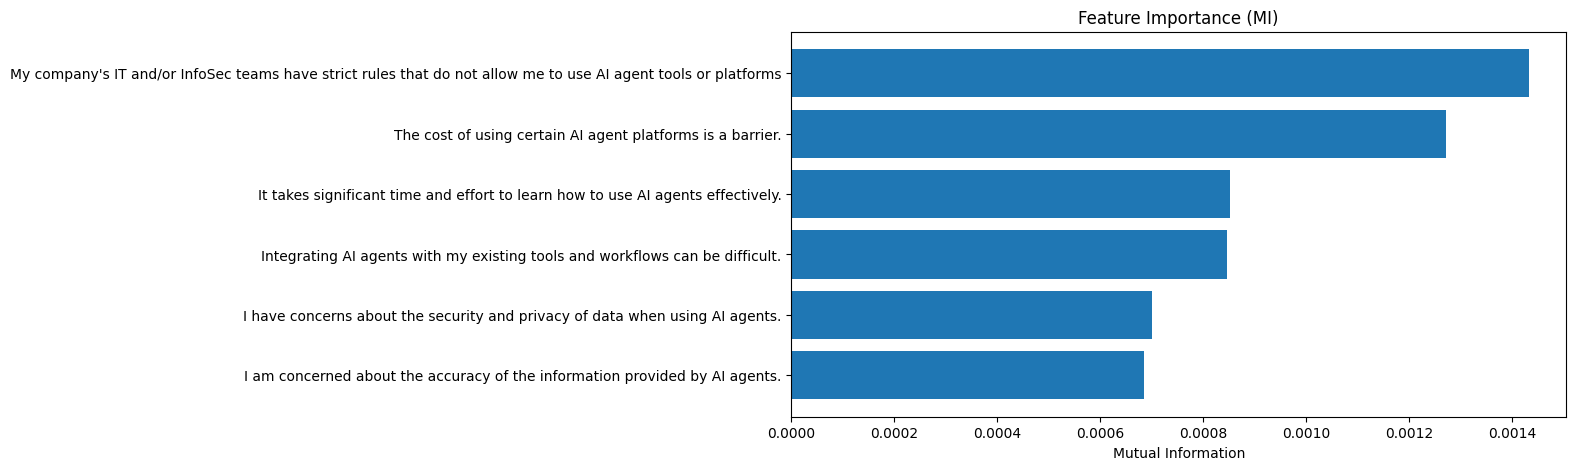

In [249]:
#mutual information
AIAgentChallenges_cols = [
    "Integrating AI agents with my existing tools and workflows can be difficult.",
    "My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms",
    "I am concerned about the accuracy of the information provided by AI agents.",
    "It takes significant time and effort to learn how to use AI agents effectively.",
    "The cost of using certain AI agent platforms is a barrier.",
    "I have concerns about the security and privacy of data when using AI agents.",
]
df = selected_cols.copy()
X = df[AIAgentChallenges_cols]
y = df["JobSatLevel"]

mi_scores = mutual_info_classif(X, y, discrete_features=True)

mi_df = pd.DataFrame({
    "Feature": AIAgentChallenges_cols,
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print(mi_df)
plt.figure(figsize=(10,5))
plt.barh(mi_df["Feature"], mi_df["MI Score"])
plt.xlabel("Mutual Information")
plt.title("Feature Importance (MI)")
plt.gca().invert_yaxis()
plt.show()

In [250]:
#try random forest model
df = selected_cols.copy()

X = df[AIAgentChallenges_cols]

y = df["JobSatLevel"]

# split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.43146254955142915


In [251]:
importance = pd.DataFrame({
    "Feature": AIAgentChallenges_cols,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(importance)

                                             Feature  Importance
0  Integrating AI agents with my existing tools a...    0.190704
5  I have concerns about the security and privacy...    0.186662
3  It takes significant time and effort to learn ...    0.185702
4  The cost of using certain AI agent platforms i...    0.154729
2  I am concerned about the accuracy of the infor...    0.147526
1  My company's IT and/or InfoSec teams have stri...    0.134676


Feature Engineering:

In [252]:
selected_cols["AI_Challenges_Total"] = selected_cols[AIAgentChallenges_cols].sum(axis=1) #sum of all agreement scores
df = selected_cols.copy()

AIAgentChallenges_cols = ["AI_Challenges_Total"]
X = df[AIAgentChallenges_cols]
y = df["JobSatLevel"]

mi_scores = mutual_info_classif(X, y, discrete_features=True)

mi_df = pd.DataFrame({
    "Feature": AIAgentChallenges_cols,
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print(mi_df)

# split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

               Feature  MI Score
0  AI_Challenges_Total  0.002246
Accuracy: 0.4721468808679324


In [253]:
#replacing AI_Challenges cloumns with sum column increased the accuracy by 4%

# AIAgent_Uses Column

In [254]:
selected_cols['AIAgent_Uses'] = selected_cols['AIAgent_Uses'].fillna('None') #fill nulls to encode
AIAgent_Uses_encoded = selected_cols["AIAgent_Uses"].str.get_dummies(sep=";") #split values and apply encoding

AIAgent_Uses_encoded.columns = [ #rename colums to "AIAgent_Uses_{value}"
    "AIAgent_Uses_" + col.strip().replace(" ", "_")
    for col in AIAgent_Uses_encoded.columns
]


#cncatinate the result with other columns
selected_cols = selected_cols.reset_index(drop=True)
AIAgent_Uses_encoded = AIAgent_Uses_encoded.reset_index(drop=True)

selected_cols = pd.concat([selected_cols, AIAgent_Uses_encoded], axis=1)
#selected_cols = selected_cols.drop(columns=["AIAgent_Uses"], errors='ignore')


In [255]:
AIAgentUses_cols = selected_cols.loc[:, selected_cols.columns.str.startswith("AIAgent_Uses")]

                                            Feature  MI Score
0          AIAgent_Uses_Business_process_automation  0.000861
7                                 AIAgent_Uses_None  0.000753
2                        AIAgent_Uses_Cybersecurity  0.000585
3                   AIAgent_Uses_Data_and_analytics  0.000537
1             AIAgent_Uses_Customer_service_support  0.000413
10                AIAgent_Uses_Software_engineering  0.000407
6                            AIAgent_Uses_Marketing  0.000355
5                        AIAgent_Uses_IT_operations  0.000241
4                AIAgent_Uses_Decision_intelligence  0.000078
8   AIAgent_Uses_Other_Industry_purpose_(write_in):  0.000063
9                             AIAgent_Uses_Robotics  0.000043


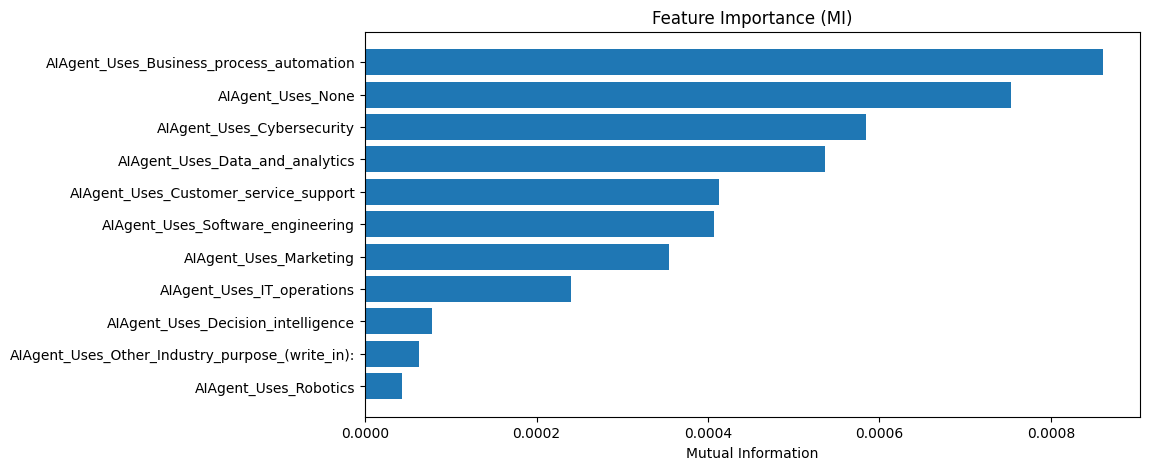

In [256]:
X = AIAgent_Uses_encoded # Use the one-hot encoded features
y = selected_cols["JobSatLevel"]

mi_scores = mutual_info_classif(X, y, discrete_features=True)

mi_df = pd.DataFrame({
    "Feature": X.columns.tolist(),
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print(mi_df)
plt.figure(figsize=(10,5))
plt.barh(mi_df["Feature"], mi_df["MI Score"])
plt.xlabel("Mutual Information")
plt.title("Feature Importance (MI)")
plt.gca().invert_yaxis()
plt.show()

In [257]:
#all MIs are very weak -> try to convert the original coumn to #AI agent uses

In [258]:
selected_cols['AIAgent_Uses_Count'] = (
    selected_cols['AIAgent_Uses']
    .fillna('')
    .apply(lambda x: 0 if x == '' else x.count(';') + 1)
)
selected_cols = selected_cols.drop(columns='AIAgent_Uses', errors='ignore')


In [259]:
X = selected_cols["AIAgent_Uses_Count"]
y = selected_cols["JobSatLevel"]

mi_scores = mutual_info_classif(X.to_frame(), y, discrete_features=True)

mi_df = pd.DataFrame({
    "Feature": ["AIAgent_Uses_Count"],
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print(mi_df)

              Feature  MI Score
0  AIAgent_Uses_Count  0.001514


## AIHuman Column

In [260]:
selected_cols['AIHuman'] = selected_cols['AIHuman'].fillna('') #fill nulls to encode
AIHuman_encoded = selected_cols["AIHuman"].str.get_dummies(sep=";") #split values and apply encoding

AIHuman_encoded.columns = [ #rename colums to "AIHuman_{value}"
    "AIHuman_" + col.strip().replace(" ", "_")
    for col in AIHuman_encoded.columns
]

In [261]:
selected_cols = selected_cols.reset_index(drop=True)
AIHuman_encoded = AIHuman_encoded.reset_index(drop=True)

selected_cols = pd.concat([selected_cols, AIHuman_encoded], axis=1)
selected_cols = selected_cols.drop(columns=["AIHuman"], errors='ignore')
selected_cols.columns

Index(['AIOpen', 'ICorPM', 'YearsCode', 'DevType', 'OrgSize', 'JobSatLevel',
       'Integrating AI agents with my existing tools and workflows can be difficult.',
       'My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms',
       'I am concerned about the accuracy of the information provided by AI agents.',
       'It takes significant time and effort to learn how to use AI agents effectively.',
       'The cost of using certain AI agent platforms is a barrier.',
       'I have concerns about the security and privacy of data when using AI agents.',
       'AI_Challenges_Total', 'AIAgent_Uses_Business_process_automation',
       'AIAgent_Uses_Customer_service_support', 'AIAgent_Uses_Cybersecurity',
       'AIAgent_Uses_Data_and_analytics', 'AIAgent_Uses_Decision_intelligence',
       'AIAgent_Uses_IT_operations', 'AIAgent_Uses_Marketing',
       'AIAgent_Uses_None', 'AIAgent_Uses_Other_Industry_purpose_(write_in):',
       'A

                                             Feature  MI Score
0  AIHuman_I_don’t_think_I’ll_need_help_from_peop...  0.000499
2            AIHuman_When_I_don’t_trust_AI’s_answers  0.000425
3  AIHuman_When_I_have_ethical_or_security_concer...  0.000393
7  AIHuman_When_I_want_to_fully_understand_something  0.000175
1                    AIHuman_Other_(please_specify):  0.000174
9  AIHuman_When_I’m_stuck_and_can’t_explain_the_p...  0.000167
8        AIHuman_When_I_want_to_learn_best_practices  0.000126
4  AIHuman_When_I_need_help_fixing_complex_or_unf...  0.000118
6  AIHuman_When_I_want_to_compare_different_solut...  0.000103
5     AIHuman_When_I_need_quick_help_troubleshooting  0.000014


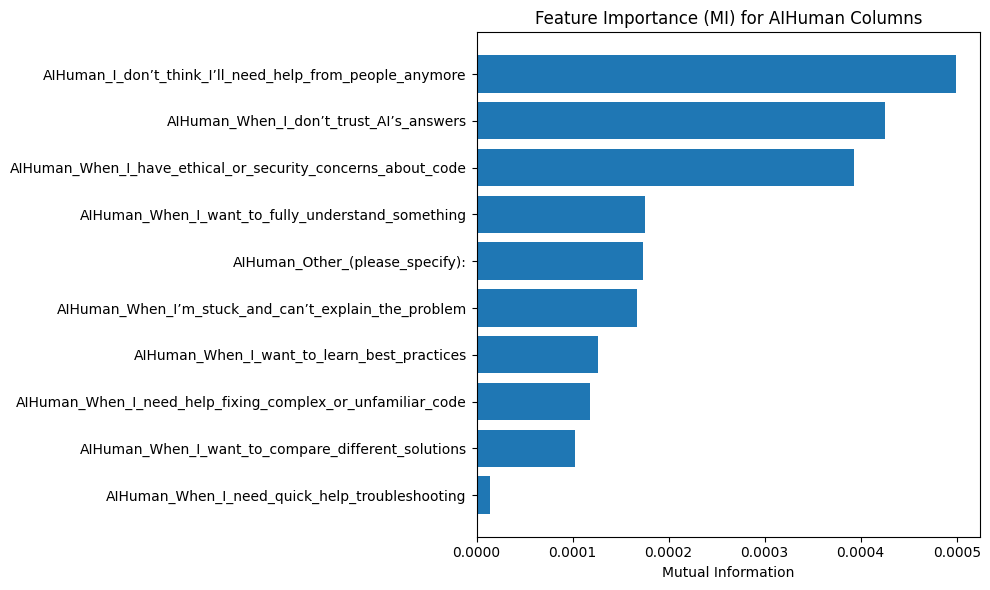

In [262]:
X = AIHuman_encoded
y = selected_cols["JobSatLevel"]

mi_scores = mutual_info_classif(X, y, discrete_features=True)

mi_df = pd.DataFrame({
    "Feature": X.columns.tolist(),
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print(mi_df)
plt.figure(figsize=(10, 6))
plt.barh(mi_df["Feature"], mi_df["MI Score"])
plt.xlabel("Mutual Information")
plt.title("Feature Importance (MI) for AIHuman Columns")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# **YearsCode**

In [263]:
# fill missing (TRAIN ONLY strategy assumed already split)
selected_cols["YearsCode"] = selected_cols["YearsCode"].fillna(selected_cols["YearsCode"].median())


### Outlier Visualization and Removal for 'YearsCode'

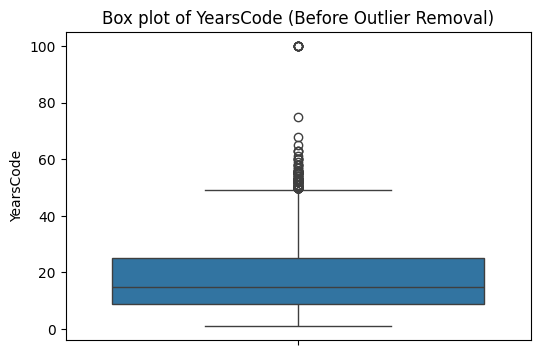

Original shape: (23961, 35)
Shape after outlier removal: (23814, 35)


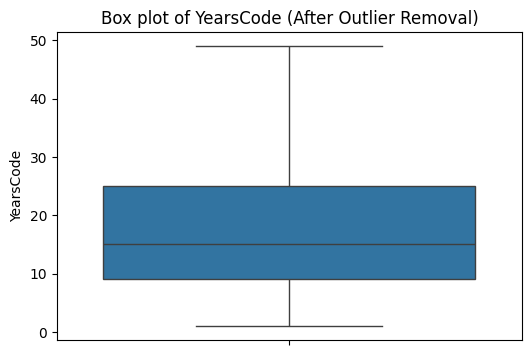


Mutual Information Scores after outlier removal (YearsCode only):
     Feature  MI Score
0  YearsCode  0.007696


In [264]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

# Ensure 'YearsCode' is numeric (coerce errors if any)
selected_cols['YearsCode'] = pd.to_numeric(selected_cols['YearsCode'], errors='coerce')

# Visualize outliers using a box plot before removal
plt.figure(figsize=(6, 4))
sns.boxplot(y=selected_cols['YearsCode'])
plt.title('Box plot of YearsCode (Before Outlier Removal)')
plt.ylabel('YearsCode')
plt.show()

# Function to remove outliers using IQR method
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_cleaned = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    return df_cleaned

print(f"Original shape: {selected_cols.shape}")

# Apply outlier removal for 'YearsCode'
selected_cols_cleaned = remove_outliers_iqr(selected_cols.copy(), 'YearsCode')

print(f"Shape after outlier removal: {selected_cols_cleaned.shape}")

# Re-visualize box plot after outlier removal to confirm
plt.figure(figsize=(6, 4))
sns.boxplot(y=selected_cols_cleaned['YearsCode'])
plt.title('Box plot of YearsCode (After Outlier Removal)')
plt.ylabel('YearsCode')
plt.show()

# Feature Selection using Mutual Information on the cleaned data for 'YearsCode'

target_col = "JobSatLevel"
feature_col = "YearsCode"

# Map 'JobSatLevel' to numeric values using the predefined jobsat_map
jobsat_map = {'Low': 1, 'Average': 2, 'High': 3}
selected_cols_cleaned[target_col] = selected_cols_cleaned[target_col].map(jobsat_map)

# Drop NaNs if any, after mapping
selected_cols_cleaned.dropna(subset=[target_col, feature_col], inplace=True)

# Prepare data for MI calculation
X_mi = selected_cols_cleaned[[feature_col]]
y_mi = selected_cols_cleaned[target_col]

# Ensure target is integer type
y_mi = y_mi.astype(int)

mi_scores = mutual_info_classif(X_mi, y_mi, discrete_features=True)

mi_df = pd.DataFrame({
    "Feature": [feature_col],
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print("\nMutual Information Scores after outlier removal (YearsCode only):")
print(mi_df)

# OrgSize

In [265]:
from sklearn.preprocessing import LabelEncoder

org_map = {
    "Just me - I am a freelancer, sole proprietor, etc.": 0,
    "Less than 20 employees": 1,
    "20 to 99 employees": 2,
    "100 to 499 employees": 3,
    "500 to 999 employees": 4,
    "1,000 to 4,999 employees": 5,
    "5,000 to 9,999 employees": 6,
    "10,000 or more employees": 7,
    "Unknown": 8,
    "I don’t know": 8
}
selected_cols["OrgSize"] = selected_cols["OrgSize"].fillna("Unknown").map(org_map)

In [266]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

# Create a copy to avoid modifying the global selected_cols for this operation
df_fs = selected_cols.copy()

target_col = "JobSatLevel"
feature_col = "OrgSize"

# Map 'JobSatLevel' to numeric values (assuming jobsat_map is available from previous cells)
jobsat_map = {'Low': 1, 'Average': 2, 'High': 3}
df_fs[target_col] = df_fs[target_col].map(jobsat_map)

# Ensure OrgSize is numeric (it should be already after mapping)
df_fs[feature_col] = pd.to_numeric(df_fs[feature_col], errors='coerce')

# Drop rows with NaN in target or feature after mapping/coercion
df_fs.dropna(subset=[target_col, feature_col], inplace=True)

# Prepare data for MI calculation
X_mi = df_fs[[feature_col]]
y_mi = df_fs[target_col]

# Ensure target is integer type
y_mi = y_mi.astype(int)

# Calculate Mutual Information
mi_scores = mutual_info_classif(X_mi, y_mi, discrete_features=True)

mi_df = pd.DataFrame({
    "Feature": [feature_col],
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print(f"Mutual Information Score for '{feature_col}':")
print(mi_df)

Mutual Information Score for 'OrgSize':
   Feature  MI Score
0  OrgSize   0.00357


# DevType

In [267]:
# Map 'JobSatLevel' to numerical values for mean calculation
jobsat_map = {'Low': 1, 'Average': 2, 'High': 3}
selected_cols['JobSatLevel_numeric'] = selected_cols['JobSatLevel'].map(jobsat_map)

# Calculate the mean JobSatLevel for each DevType using the numeric column
dev_mean = selected_cols.groupby('DevType')['JobSatLevel_numeric'].mean()

# Map the mean back to the original DevType column to create the encoded feature
selected_cols['DevType_encoded'] = selected_cols['DevType'].map(dev_mean)

# Optionally, you can drop the temporary 'JobSatLevel_numeric' column if not needed later
selected_cols = selected_cols.drop(columns=['JobSatLevel_numeric'], errors='ignore')

In [268]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

df_fs = selected_cols.copy()

target_col = "JobSatLevel"
feature_col = "DevType_encoded"

# Map 'JobSatLevel' to numeric values
jobsat_map = {'Low': 1, 'Average': 2, 'High': 3}
df_fs[target_col] = df_fs[target_col].map(jobsat_map)

# Ensure feature column is numeric
df_fs[feature_col] = pd.to_numeric(df_fs[feature_col], errors='coerce')

# Prepare data for MI calculation
X_mi = df_fs[[feature_col]]
y_mi = df_fs[target_col]

# Ensure target is integer type
y_mi = y_mi.astype(int)

# Calculate Mutual Information
mi_scores = mutual_info_classif(X_mi, y_mi, discrete_features=True)

mi_df = pd.DataFrame({
    "Feature": [feature_col],
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print(f"Mutual Information Score for '{feature_col}':")
print(mi_df)


Mutual Information Score for 'DevType_encoded':
           Feature  MI Score
0  DevType_encoded   0.00742


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/cluster/_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and multiclass values for target
  warnings.warn(msg, UserWarning)


In [269]:
def group_dev_type(dev_type):
    if pd.isna(dev_type):
        return 'Unknown'

    dev_type = str(dev_type)

    if any(k in dev_type for k in ['back-end','front-end','full-stack','mobile','desktop','embedded','game','Architect','QA']):
        return 'Software Engineering'

    elif any(k in dev_type for k in ['Data scientist','Data engineer','AI/ML','AI apps','Applied scientist','Data or business analyst']):
        return 'Data & AI'

    elif any(k in dev_type for k in ['Cloud','DevOps','System administrator','Database','Cybersecurity','Support']):
        return 'Infrastructure & Ops'

    elif any(k in dev_type for k in ['manager','executive','Founder','VP','Product']):
        return 'Leadership & Product'

    else:
        return 'Other'

selected_cols['DevType_Grouped'] = selected_cols['DevType'].apply(group_dev_type)

# ICorPM

In [270]:
#handelling missing values
selected_cols["ICorPM"] = selected_cols["ICorPM"].fillna("Unknown")
le = LabelEncoder()
selected_cols['ICorPM'] = le.fit_transform(selected_cols['ICorPM'])

In [271]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

df_fs = selected_cols.copy()

target_col = "JobSatLevel"
feature_col = "ICorPM"

# Map 'JobSatLevel' to numeric values
jobsat_map = {'Low': 1, 'Average': 2, 'High': 3}
df_fs[target_col] = df_fs[target_col].map(jobsat_map)

# Ensure feature column is numeric
df_fs[feature_col] = pd.to_numeric(df_fs[feature_col], errors='coerce')

# Drop rows with NaN in target or feature after mapping/coercion
df_fs.dropna(subset=[target_col, feature_col], inplace=True)

# Prepare data for MI calculation
X_mi = df_fs[[feature_col]]
y_mi = df_fs[target_col]

# Ensure target is integer type
y_mi = y_mi.astype(int)

# Calculate Mutual Information
mi_scores = mutual_info_classif(X_mi, y_mi, discrete_features=True)

mi_df = pd.DataFrame({
    "Feature": [feature_col],
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print(f"Mutual Information Score for '{feature_col}':")
print(mi_df)


Mutual Information Score for 'ICorPM':
  Feature  MI Score
0  ICorPM   0.00313


# Final conclusion

In [272]:
for col in selected_cols.columns:
    print(f"\n--- Column: {col} ---")
    # Convert to string to handle mixed types if any, and then get value counts
    display(selected_cols[col].astype(str).value_counts())
    print("-"*50)


--- Column: AIOpen ---


,count
AIOpen,
nan,8636
Problem solving,86
Critical thinking,69
Debugging,58
problem solving,55
...,...
"All the skills that AI will attain last - long attention, complex issue resolving, connecting ideas that make innovations that are good for real life.",1
Yes as long there is a need for understandig the code the Value will be there,1
Soft skills with people and software maintenance skills.,1


--------------------------------------------------

--- Column: ICorPM ---


,count
ICorPM,
0,17533
2,3752
1,2676


--------------------------------------------------

--- Column: YearsCode ---


,count
YearsCode,
15.0,1741
10.0,1702
20.0,1560
8.0,1162
25.0,1129
...,...
65.0,1
75.0,1
59.0,1


... (65 outputs left out)

,count
DevType_encoded,
1.9531990521327014,8440
1.8984552476147205,4402
2.084967320261438,1683
1.9621913580246915,1296
1.8720190779014307,1258
1.974025974025974,924
1.9463470319634704,876
1.965391621129326,549
2.0037593984962405,532


--------------------------------------------------

--- Column: DevType_Grouped ---


,count
DevType_Grouped,
Software Engineering,19302
Data & AI,1408
Other,1132
Leadership & Product,1097
Infrastructure & Ops,1022


--------------------------------------------------


In [273]:
unique_values_count = selected_cols.nunique()
print("Number of unique values in each column:\n", unique_values_count)

Number of unique values in each column:
 AIOpen                                                                                                            13884
ICorPM                                                                                                                3
YearsCode                                                                                                            66
DevType                                                                                                              32
OrgSize                                                                                                               9
JobSatLevel                                                                                                           3
Integrating AI agents with my existing tools and workflows can be difficult.                                          4
My company's IT and/or InfoSec teams have strict rules that do not allow me to use AI agent tools or platforms        4

/tmp/ipykernel_31035/2026019928.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = pd.to_numeric(X[col], errors='coerce')


Mutual Information Scores for all features:
                                              Feature  MI Score
1                                           YearsCode  0.004717
2                                             OrgSize  0.003570
0                                              ICorPM  0.003130
9                                 AI_Challenges_Total  0.002246
21                                 AIAgent_Uses_Count  0.001514
4   My company's IT and/or InfoSec teams have stri...  0.001433
7   The cost of using certain AI agent platforms i...  0.001272
10           AIAgent_Uses_Business_process_automation  0.000861
6   It takes significant time and effort to learn ...  0.000852
3   Integrating AI agents with my existing tools a...  0.000847
17                                  AIAgent_Uses_None  0.000753
8   I have concerns about the security and privacy...  0.000701
5   I am concerned about the accuracy of the infor...  0.000684
12                         AIAgent_Uses_Cybersecurity  0.000

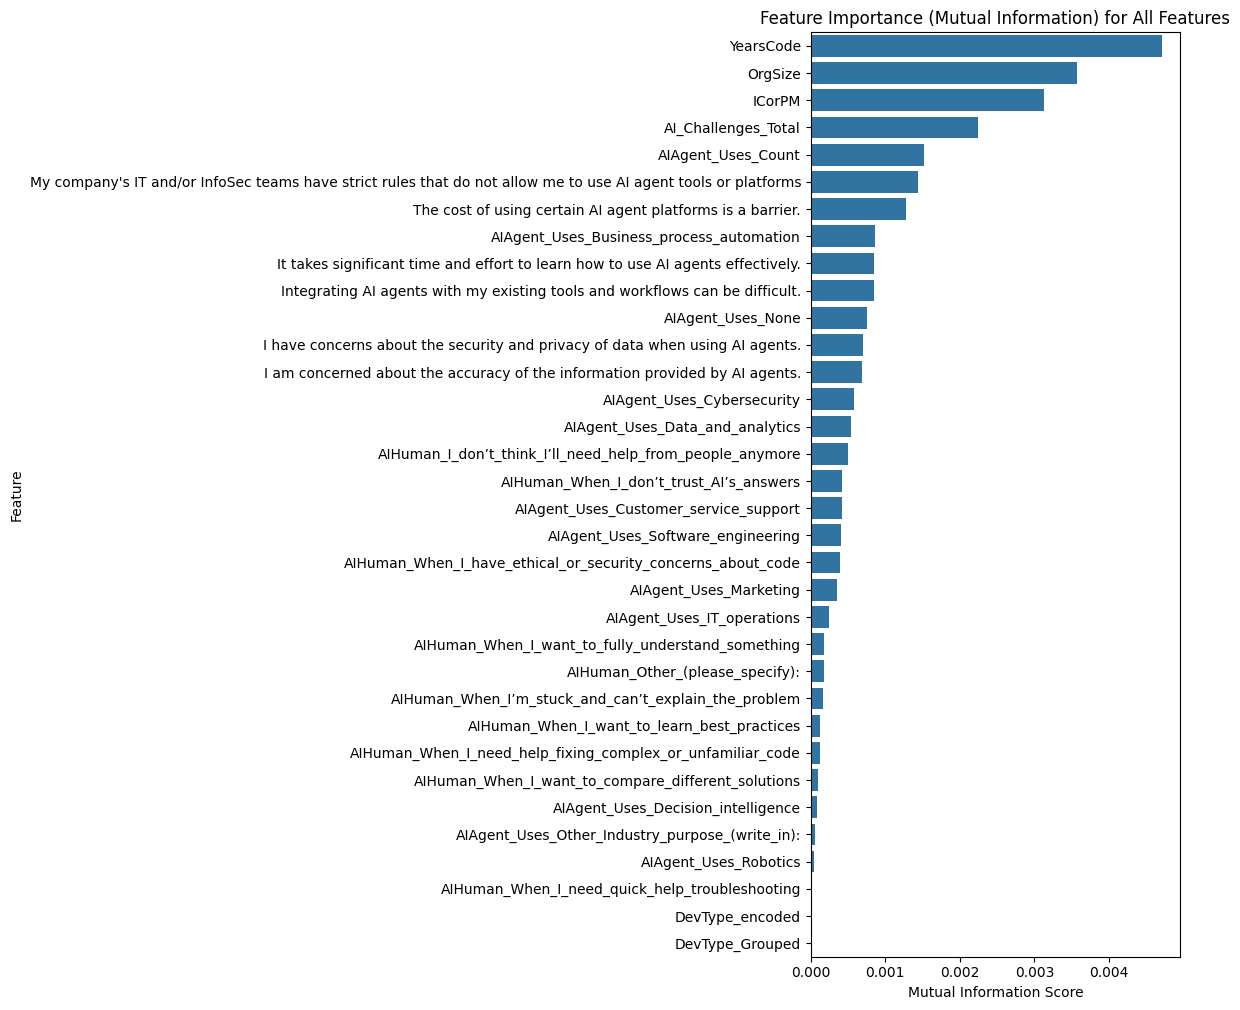

In [275]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

# Make a copy to avoid modifying the original DataFrame unintentionally
df_fs_all = selected_cols.copy()

# Drop the 'AIOpen' column as it's free text and requires specialized NLP for feature extraction
# and also 'DevType' since 'DevType_encoded' is already created.
df_fs_all = df_fs_all.drop(columns=['AIOpen', 'DevType'], errors='ignore')

# Define target and features
target_col = "JobSatLevel"

# Map 'JobSatLevel' to numeric values if not already done
# Re-apply mapping here to ensure consistency, handling potential string types
jobsat_map = {'Low': 1, 'Average': 2, 'High': 3}
df_fs_all[target_col] = df_fs_all[target_col].map(jobsat_map)

# Drop rows with NaN in the target column after mapping
df_fs_all.dropna(subset=[target_col], inplace=True)

# Ensure target is integer type
df_fs_all[target_col] = df_fs_all[target_col].astype(int)

# Identify feature columns (all columns except the target)
feature_cols = [col for col in df_fs_all.columns if col != target_col]
X = df_fs_all[feature_cols]
y = df_fs_all[target_col]

# Convert all object columns in X to numeric (e.g., if there are remaining mixed types)
for col in X.select_dtypes(include='object').columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# Fill any NaNs in X before passing to mutual_info_classif
X = X.fillna(0)

# Identify discrete features. For this dataset, many features are already encoded as discrete.
# For safety, we can use a threshold for unique values or explicitly list them.
discrete_features_mask = [col in ['ICorPM', 'OrgSize', 'AIAgent_Uses_Count'] or X[col].nunique() < 20 for col in X.columns]

mi_scores = mutual_info_classif(X, y, discrete_features=discrete_features_mask, random_state=42)

mi_df = pd.DataFrame({
    "Feature": X.columns,
    "MI Score": mi_scores
}).sort_values(by="MI Score", ascending=False)

print("Mutual Information Scores for all features:")
print(mi_df)

plt.figure(figsize=(12, max(8, len(mi_df) * 0.3)))
sns.barplot(x="MI Score", y="Feature", data=mi_df)
plt.title("Feature Importance (Mutual Information) for All Features")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [276]:
columns_to_keep = [
    'YearsCode',
    'OrgSize',
    'ICorPM',
    'AI_Challenges_Total',
    'AIAgent_Uses_Count',
    'JobSatLevel' # Keep the target variable
]

selected_cols = selected_cols[columns_to_keep].copy()

print("DataFrame after dropping columns:")
print(selected_cols.head())
print(f"New shape: {selected_cols.shape}")

DataFrame after dropping columns:
   YearsCode  OrgSize  ICorPM  AI_Challenges_Total  AIAgent_Uses_Count  \
0       14.0        2       1                 20.0                   1   
1       10.0        4       0                 24.0                   1   
2       12.0        8       2                 20.0                   1   
3        5.0        7       0                 25.0                   1   
4       20.0        8       2                 24.0                   4   

  JobSatLevel  
0        High  
1        High  
2     Average  
3         Low  
4     Average  
New shape: (23961, 6)
